# Import Libraries

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shivasingh4945/student-social-media-and-mental-health-impact/Student Social Media And Mental Health Impact.csv


# Load Dataset

In [2]:
df= pd.read_csv('/kaggle/input/datasets/shivasingh4945/student-social-media-and-mental-health-impact/Student Social Media And Mental Health Impact.csv')

In [3]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [4]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [5]:
df.describe(include="object")

,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Stress_Level
count,5000,5000,5000,5000,5000,5000
unique,2,111,3,12,4,4
top,Male,Other,Undergraduate,Instagram,Entertainment,Very High
freq,2635,1880,3632,1130,2552,1621


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [7]:
df.isnull().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

# Data Cleaning

In [8]:
df_raw = df.copy()

df_clean = df_raw.drop_duplicates().copy()

# Negative activity values are invalid, so mark them as missing
df_clean.loc[
    df_clean["Physical_Activity_Hours"] < 0,
    "Physical_Activity_Hours"
] = np.nan

print("Original shape:", df_raw.shape)
print("Cleaned shape:", df_clean.shape)
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Original shape: (5000, 13)
Cleaned shape: (4998, 13)

Missing values after cleaning:
Age                         0
Gender                      0
Country                     0
Academic_Level              0
Most_Used_Platform          0
Purpose_Of_Use              0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 0
Physical_Activity_Hours    10
Sleep_Hours_Per_Night       0
Stress_Level                0
Mental_Health_Score         0
dtype: int64


In [9]:
print("Duplicates remaining:", df_clean.duplicated().sum())
print("Missing values:")
print(df_clean.isnull().sum())

Duplicates remaining: 0
Missing values:
Age                         0
Gender                      0
Country                     0
Academic_Level              0
Most_Used_Platform          0
Purpose_Of_Use              0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 0
Physical_Activity_Hours    10
Sleep_Hours_Per_Night       0
Stress_Level                0
Mental_Health_Score         0
dtype: int64


# Exploratory Data Analysis (EDA) & Data Visualization

In [10]:
print("Duplicates remaining:", df_clean.duplicated().sum())
print("Missing values:")
print(df_clean.isnull().sum())

Duplicates remaining: 0
Missing values:
Age                         0
Gender                      0
Country                     0
Academic_Level              0
Most_Used_Platform          0
Purpose_Of_Use              0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 0
Physical_Activity_Hours    10
Sleep_Hours_Per_Night       0
Stress_Level                0
Mental_Health_Score         0
dtype: int64


count    4998.000000
mean        6.231152
std         1.278476
min         3.600000
25%         5.100000
50%         6.100000
75%         7.100000
max         9.400000
Name: Mental_Health_Score, dtype: float64


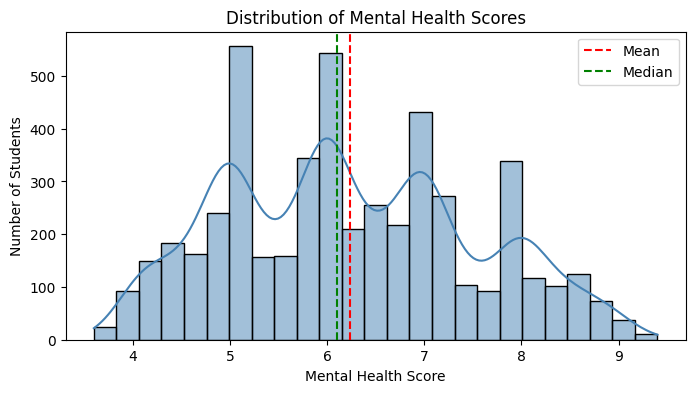

In [11]:
# Target distribution
target = "Mental_Health_Score"

print(df_clean[target].describe())

plt.figure(figsize=(8, 4))
sns.histplot(df_clean[target], bins=25, kde=True, color="steelblue")

plt.axvline(
    df_clean[target].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    df_clean[target].median(),
    color="green",
    linestyle="--",
    label="Median"
)

plt.title("Distribution of Mental Health Scores")
plt.xlabel("Mental Health Score")
plt.ylabel("Number of Students")
plt.legend()
plt.show()

Avg_Daily_Usage_Hours     -0.816485
Daily_Unlocks             -0.790830
Sleep_Hours_Per_Night      0.766462
Study_Hours                0.752483
Physical_Activity_Hours    0.520617
Age                        0.100464
Name: Mental_Health_Score, dtype: float64


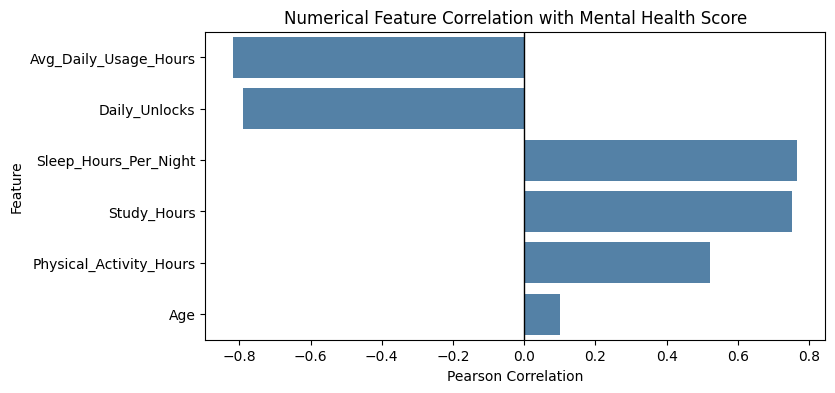

In [12]:
# Correlation between numerical features and the target
numeric_columns = df_clean.select_dtypes(include="number").columns

target_corr = (
    df_clean[numeric_columns]
    .corr()[target]
    .drop(target)
    .sort_values(key=np.abs, ascending=False)
)

print(target_corr)

plt.figure(figsize=(8, 4))
sns.barplot(
    x=target_corr.values,
    y=target_corr.index,
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Numerical Feature Correlation with Mental Health Score")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.show()

In [13]:
analysis_columns = [
    "Avg_Daily_Usage_Hours",
    "Daily_Unlocks",
    "Study_Hours",
    "Physical_Activity_Hours",
    "Sleep_Hours_Per_Night",
    "Mental_Health_Score"
]

In [14]:
df_clean.groupby("Academic_Level")[analysis_columns].mean()

,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
Academic_Level,,,,,,
Graduate,4.939760,167.944444,3.173094,1.749672,6.688017,6.391176
High School,5.428222,180.908889,2.717556,1.680000,6.112889,5.864000
Undergraduate,5.070220,171.171625,3.002810,1.765213,6.685840,6.236198


In [15]:
df_clean.groupby("Age")[analysis_columns].mean()

,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
Age,,,,,,
18,5.428222,180.908889,2.717556,1.680000,6.112889,5.864000
19,5.165304,173.855249,2.880000,1.720598,6.596796,6.142210
20,5.072593,171.946772,2.922424,1.804892,6.709060,6.228426
21,5.058245,170.511628,3.093023,1.782627,6.666068,6.240803
22,4.984487,168.393973,3.110826,1.752902,6.773772,6.333929
23,4.905040,166.816532,3.147984,1.815960,6.715524,6.386694
24,4.980569,169.270142,3.202607,1.671734,6.655687,6.396445


In [16]:
df_clean.groupby("Gender")[analysis_columns].mean()

,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
Gender,,,,,,
Female,5.126904,173.024958,2.965905,1.751334,6.610575,6.186168
Male,5.035042,170.047077,3.046545,1.757670,6.656264,6.271526


In [17]:
df_clean[numeric_columns].groupby(df_clean['Purpose_Of_Use'])[['Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Mental_Health_Score']].mean() 

,Avg_Daily_Usage_Hours,Daily_Unlocks,Mental_Health_Score
Purpose_Of_Use,,,
Education,5.013724,170.015554,6.350961
Entertainment,5.109761,172.026656,6.114700
Networking,4.982219,169.064313,6.378562
News,5.198574,175.044563,6.318895


In [18]:
category_columns = [
    "Stress_Level",
    "Academic_Level",
    "Purpose_Of_Use",
    "Most_Used_Platform"
]

for column in category_columns:
    print(f"\nMental health score by {column}:")
    display(
        df_clean.groupby(column)[target]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )


Mental health score by Stress_Level:


,count,mean,median
Stress_Level,,,
Low,643,7.840747,8.0
Medium,1295,7.135907,7.0
High,1439,6.026755,6.0
Very High,1621,5.051326,5.0



Mental health score by Academic_Level:


,count,mean,median
Academic_Level,,,
Graduate,918,6.391176,6.2
Undergraduate,3630,6.236198,6.1
High School,450,5.864000,5.6



Mental health score by Purpose_Of_Use:


,count,mean,median
Purpose_Of_Use,,,
Networking,793,6.378562,6.6
Education,1093,6.350961,6.4
News,561,6.318895,6.1
Entertainment,2551,6.114700,6.0



Mental health score by Most_Used_Platform:


,count,mean,median
Most_Used_Platform,,,
LINE,50,8.024000,8.00
VKontakte,40,7.002500,7.00
WeChat,36,6.494444,6.25
LinkedIn,522,6.487165,6.50
Facebook,719,6.398331,6.70
Twitter,462,6.346753,6.30
YouTube,491,6.216497,6.10
Instagram,1130,6.194071,6.00
Snapchat,419,6.119809,6.00


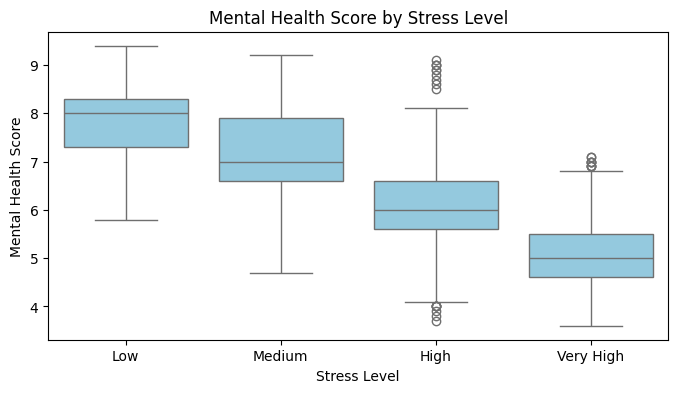

In [19]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df_clean,
    x="Stress_Level",
    y=target,
    order=["Low", "Medium", "High", "Very High"],
    color="skyblue"
)

plt.title("Mental Health Score by Stress Level")
plt.xlabel("Stress Level")
plt.ylabel("Mental Health Score")
plt.show()

# Preparing Data for modeling

In [20]:
from sklearn.model_selection import train_test_split

# X contains predictors; y is the value we want to predict
X = df_clean.drop(columns=target)
y = df_clean[target]

# Reserve 20% of the data for an unbiased final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

Training features: (3998, 12)
Test features: (1000, 12)
Training target: (3998,)
Test target: (1000,)


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical predictor columns
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# For numerical columns:
# 1. Replace missing values with the training median.
# 2. Scale values so features are comparable for linear models.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# For categorical columns:
# 1. Fill any missing category with its most common value.
# 2. Convert categories to 0/1 indicator columns.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct pipeline to each group of columns
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

Numerical features: ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night']
Categorical features: ['Gender', 'Country', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use', 'Stress_Level']


# Model Testing and Evaluation

## Ridge Regression

Ridge Regression is used as the baseline model for predicting the mental-health score.

It was selected as a starting point because the exploratory analysis revealed strong linear relationships between several predictors and the target. Ridge Regression also uses L2 regularization to help control overfitting.

Model performance will be evaluated using **MAE, RMSE, and R²**.

In [22]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Combine preprocessing and modelling in one leakage-safe workflow
ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

# Fit using training data only
ridge_model.fit(X_train, y_train)

# Predict scores for the untouched test set
y_pred = ridge_model.predict(X_test)

# Evaluate prediction quality
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  0.476
RMSE: 0.613
R²:   0.790


## Random Forest Regression

To capture potential non-linear relationships and interactions between the predictors, a Random Forest Regressor is trained as a second model.

The model will be evaluated using **MAE, RMSE, and R²** and compared with the Ridge Regression baseline.

In [23]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Train and predict
random_forest_model.fit(X_train, y_train)
y_pred_rf = random_forest_model.predict(X_test)

# Evaluate
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest MAE:  {mae_rf:.3f}")
print(f"Random Forest RMSE: {rmse_rf:.3f}")
print(f"Random Forest R²:   {r2_rf:.3f}")

Random Forest MAE:  0.276
Random Forest RMSE: 0.383
Random Forest R²:   0.918


I want to figure out which Varible contributed the most to the Random Forest's predictions

In [24]:
# Get the fitted preprocessing step
preprocessor_fitted = random_forest_model.named_steps["preprocessor"]

# Get the Random Forest model
rf = random_forest_model.named_steps["model"]

# Get the names of all transformed features
feature_names = preprocessor_fitted.get_feature_names_out()

# Get feature importance values
importances = rf.feature_importances_

# Put them into a DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort from most important to least important
feature_importance_df = feature_importance_df.sort_values(
    "Importance",
    ascending=False
)

# Display the top 15
display(feature_importance_df.head(15))

,Feature,Importance
1,num__Avg_Daily_Usage_Hours,0.682607
5,num__Sleep_Hours_Per_Night,0.097818
2,num__Daily_Unlocks,0.027120
4,num__Physical_Activity_Hours,0.017093
3,num__Study_Hours,0.017057
76,cat__Country_Pakistan,0.016283
18,cat__Country_Bangladesh,0.012700
0,num__Age,0.010550
75,cat__Country_Other,0.009310
93,cat__Country_Spain,0.009166


## Exploring Relationships Between Key Features and Mental Health Score

To better understand the relationships identified during the exploratory analysis, scatter plots are used to examine how the two key numerical features relate to the mental-health score.

The plots focus on:
- `Avg_Daily_Usage_Hours`
- `Sleep_Hours_Per_Night`

Regression lines are included to help visualize the direction and strength of the linear relationships.

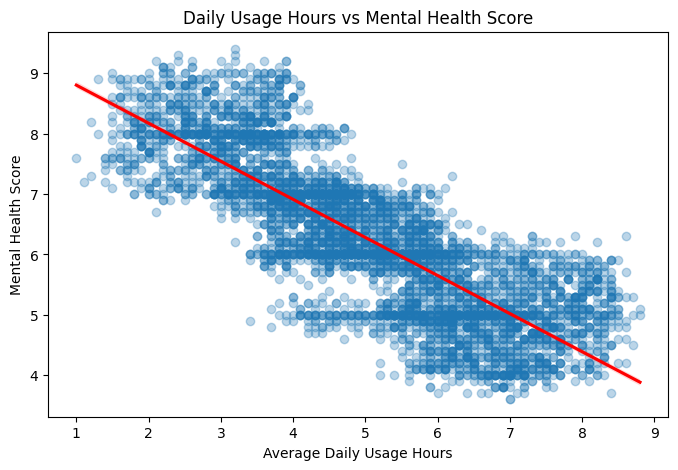

In [25]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_clean,
    x="Avg_Daily_Usage_Hours",
    y=target,
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Daily Usage Hours vs Mental Health Score")
plt.xlabel("Average Daily Usage Hours")
plt.ylabel("Mental Health Score")
plt.show()

In [26]:
correlation = df_clean["Avg_Daily_Usage_Hours"].corr(df_clean[target])

print(f"Correlation: {correlation:.3f}")

Correlation: -0.816


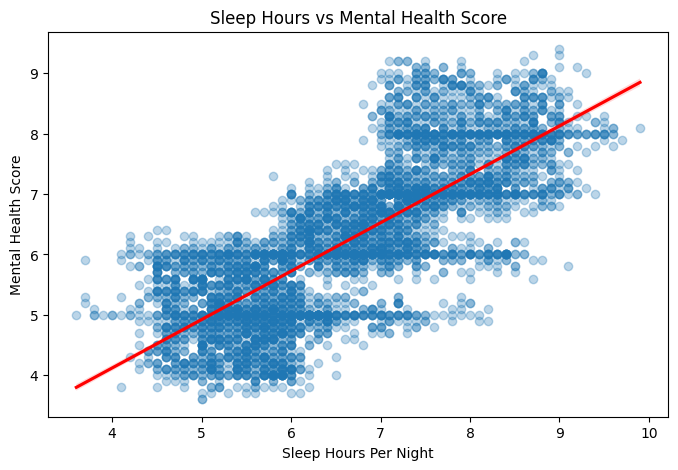

In [27]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_clean,
    x="Sleep_Hours_Per_Night",
    y=target,
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Sleep Hours vs Mental Health Score")
plt.xlabel("Sleep Hours Per Night")
plt.ylabel("Mental Health Score")
plt.show()

In [28]:
sleep_correlation = df_clean["Sleep_Hours_Per_Night"].corr(df_clean[target])

print(f"Sleep correlation: {sleep_correlation:.3f}")

Sleep correlation: 0.766


## Cross-Validation of the Random Forest Model

Although the Random Forest performed well on the test set, a single train-test split may not fully represent how the model performs on unseen data.

Therefore, **5-fold cross-validation** is used to evaluate the model across multiple subsets of the training data. The mean and standard deviation of **MAE, RMSE, and R²** are used to assess the model's performance and consistency.

In [29]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "mse": "neg_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=1
)

cv_mae = -cv_scores["test_mae"]
cv_rmse = np.sqrt(-cv_scores["test_mse"])
cv_r2 = cv_scores["test_r2"]

print(f"CV MAE:  {cv_mae.mean():.3f} ± {cv_mae.std():.3f}")
print(f"CV RMSE: {cv_rmse.mean():.3f} ± {cv_rmse.std():.3f}")
print(f"CV R²:   {cv_r2.mean():.3f} ± {cv_r2.std():.3f}")

CV MAE:  0.294 ± 0.013
CV RMSE: 0.403 ± 0.016
CV R²:   0.898 ± 0.007


# Results Explanation and Conclusion

### Results Explanation

The analysis identified several important patterns in the dataset.

- `Avg_Daily_Usage_Hours` had a strong negative correlation with the mental-health score (**r = -0.816**), indicating that higher daily usage was associated with lower mental-health scores.
- `Sleep_Hours_Per_Night` had a strong positive correlation with the mental-health score (**r = 0.766**), indicating that higher sleep duration was associated with higher mental-health scores.
- Mental-health scores also decreased consistently as `Stress_Level` increased from **Low → Medium → High → Very High**.

Two regression models were evaluated. Ridge Regression achieved an **MAE of 0.476, RMSE of 0.613, and R² of 0.790**. The Random Forest Regressor performed better on the test set, achieving an **MAE of 0.276, RMSE of 0.383, and R² of 0.918**.

The Random Forest feature-importance analysis showed that `Avg_Daily_Usage_Hours` was the most important predictor, followed by `Sleep_Hours_Per_Night`. This is consistent with the strong correlations observed during the exploratory analysis.

The results from cross-validation were used to determine whether the model's performance remained reasonably consistent across different subsets of the training data.


# Conclusion

From the analysis, `Avg_Daily_Usage_Hours` and `Sleep_Hours_Per_Night` were among the strongest predictors of `Mental_Health_Score`. Daily usage showed a strong negative relationship with the target, while sleep duration showed a strong positive relationship.